# TP5 — Arbres et ensembles

**Cours :** Introduction au Machine Learning — 60 h — Licence 3 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 3 h · **Barème :** 15 points

---

## Objectifs

- Faire pousser un arbre et le régulariser.
- Comparer arbre, forêt et boosting à coût égal.
- Lire deux mesures d'importance et expliquer leur écart.
- Régler un boosting par arrêt anticipé.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU en moins de deux minutes.
- Les cellules **« À vous »** sont évaluées. Graine fixée.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(4112)
print('environnement pret')

environnement pret


## 1. Les données

Jeu **digits** (fourni avec scikit-learn) : 1 797 images 8×8, 10 classes.
Chaque image est une ligne de 64 pixels.

In [2]:
from sklearn.datasets import load_digits
X, y = load_digits(return_X_y=True, as_frame=True)
print("formes :", X.shape)
print("classes :", sorted(y.unique()))

formes : (1797, 64)
classes : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## 2. Découper

In [3]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=4112, stratify=y)
print("entrainement :", Xtr.shape, "| test :", Xte.shape)

entrainement : (1347, 64) | test : (450, 64)


## 3. Faire pousser un arbre jusqu'au surapprentissage

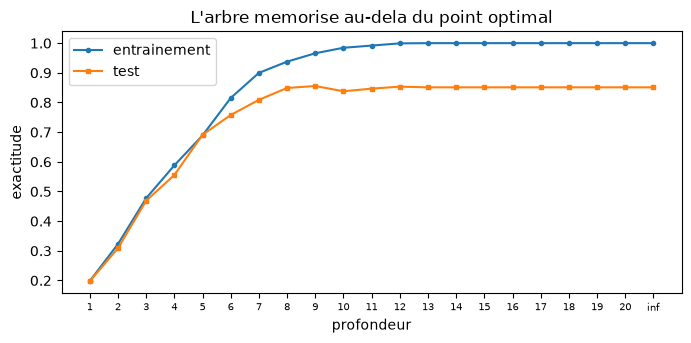

exactitude test maximale : 0.856 a la profondeur 9


In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

profondeurs = list(range(1, 21)) + [None]
tr, te = [], []
for p in profondeurs:
    m = DecisionTreeClassifier(max_depth=p, random_state=4112).fit(Xtr, ytr)
    tr.append(accuracy_score(ytr, m.predict(Xtr)))
    te.append(accuracy_score(yte, m.predict(Xte)))

plt.figure(figsize=(8, 3.4))
plt.plot(range(len(profondeurs)), tr, "o-", ms=3, label="entrainement")
plt.plot(range(len(profondeurs)), te, "s-", ms=3, label="test")
plt.xticks(range(len(profondeurs)), [str(p) if p else "inf" for p in profondeurs], fontsize=7)
plt.xlabel("profondeur"); plt.ylabel("exactitude"); plt.legend()
plt.title("L'arbre memorise au-dela du point optimal")
plt.show()
print("exactitude test maximale :", round(max(te), 3),
      "a la profondeur", profondeurs[int(np.argmax(te))])

## 4. Arbre, forêt, boosting

In [5]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import time

modeles = {
    "Arbre (prof. 5)": DecisionTreeClassifier(max_depth=5, random_state=4112),
    "Foret (300)": RandomForestClassifier(n_estimators=300, random_state=4112, n_jobs=2),
    "Boosting (200)": GradientBoostingClassifier(n_estimators=200, random_state=4112),
}
lignes = []
for nom, mdl in modeles.items():
    t0 = time.time(); mdl.fit(Xtr, ytr); d = time.time() - t0
    lignes.append((nom, round(float(accuracy_score(yte, mdl.predict(Xte))), 4), round(d, 2)))
print(pd.DataFrame(lignes, columns=["modele", "exactitude", "temps_s"]).to_string(index=False))

         modele  exactitude  temps_s
Arbre (prof. 5)      0.6911     0.02
    Foret (300)      0.9689     1.14
 Boosting (200)      0.9689    16.98


## 5. Combien d'arbres faut-il ?

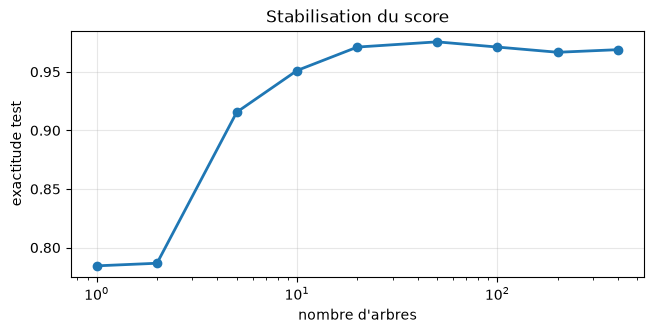

   1 arbres : 0.7844
   2 arbres : 0.7867
   5 arbres : 0.9156
  10 arbres : 0.9511
  20 arbres : 0.9711
  50 arbres : 0.9756
 100 arbres : 0.9711
 200 arbres : 0.9667
 400 arbres : 0.9689


In [6]:
ns = [1, 2, 5, 10, 20, 50, 100, 200, 400]
scores = []
for n in ns:
    m = RandomForestClassifier(n_estimators=n, random_state=4112, n_jobs=2).fit(Xtr, ytr)
    scores.append(accuracy_score(yte, m.predict(Xte)))

plt.figure(figsize=(7.4, 3.2))
plt.semilogx(ns, scores, "o-", lw=2)
plt.xlabel("nombre d'arbres"); plt.ylabel("exactitude test")
plt.title("Stabilisation du score")
plt.grid(alpha=.3); plt.show()
for n, s in zip(ns, scores):
    print(f"{n:4d} arbres : {s:.4f}")

## 6. Importance des variables : deux méthodes

On change de jeu pour avoir des **noms de variables lisibles** :
`breast_cancer` (30 mesures cliniques).

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.inspection import permutation_importance

Xb, yb = load_breast_cancer(return_X_y=True, as_frame=True)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=.3, random_state=4112, stratify=yb)
foret = RandomForestClassifier(n_estimators=300, random_state=4112, n_jobs=2).fit(Xb_tr, yb_tr)

mdi = pd.Series(foret.feature_importances_, index=Xb.columns)
perm = permutation_importance(foret, Xb_te, yb_te, n_repeats=10, random_state=4112, n_jobs=2)
perm_s = pd.Series(perm.importances_mean, index=Xb.columns)

comp = pd.DataFrame({"MDI": mdi, "permutation": perm_s}).sort_values("permutation", ascending=False)
print(comp.head(10).round(3).to_string())

                          MDI  permutation
worst texture           0.024        0.006
mean texture            0.020        0.005
worst concave points    0.117        0.004
worst radius            0.108        0.002
worst symmetry          0.013        0.001
worst area              0.115        0.001
mean concavity          0.041        0.000
mean fractal dimension  0.005        0.000
texture error           0.005        0.000
mean radius             0.038        0.000


## 7. Arrêt anticipé

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=1000,
                                     early_stopping=True, n_iter_no_change=20,
                                     validation_fraction=0.15,
                                     random_state=4112).fit(Xtr, ytr)
print("iterations retenues :", hgb.n_iter_, "sur 1000 demandees")
print("exactitude test     :", round(float(accuracy_score(yte, hgb.predict(Xte))), 4))

iterations retenues : 254 sur 1000 demandees
exactitude test     : 0.9667


## 8. À vous (noté)

**1.** Dans la section 3, à quelle profondeur l'écart entre entraînement et
test devient-il supérieur à 0,10 ? Citez la profondeur et les deux exactitudes.

**2.** Dans la section 6, comparez le classement MDI et le classement par
permutation. Donnez **une** variable dont le rang change de plus de 5 places et
expliquez pourquoi la MDI la favorise.

**3.** Dans la section 7, baissez `learning_rate` à 0,01. Le nombre d'itérations
retenues augmente-t-il ? Le score s'améliore-t-il ? Concluez sur le compromis.

In [9]:
# ---- A VOUS ----
# 1)
# 2)
# 3)

## 9. Ce qu'il faut retenir

| Geste | Pourquoi |
|---|---|
| commencer par un arbre court | lisible, et montre ce qui compte |
| régler la profondeur par validation | l'entraînement atteint toujours 1,0 |
| forêt comme référence | robuste, peu de réglage |
| boosting avec arrêt anticipé | les derniers points, au prix du temps |
| permutation sur le test | la MDI est biaisée |